1. Написать свой класс для модели линейной регрессии.
2. Описать метод predict() для использования обученной модели.
3. Решить проблему масштабирования данных: для корректной работы алгоритма данные должны быть нормированы, но для дальнейшего прогнозирования данные должны подаваться в исходном не отмасштабированном виде.
4. Модель должна работать с данными любой размерности (любым количеством признаков).
5. Операции должны быть максимально векторизованы (то есть не нужно в цикле проходить по всем объектам, а нужно одновременно обрабатывать все в матричном виде).
6. Построить модель линейной регрессии для данных из файла data.csv
https://drive.google.com/file/d/1MK4yFiHcsKST5sDkfpFCPDrgyVp_eCQu/view?usp=sharing </br> Найти коэффициенты регрессии и построить график.

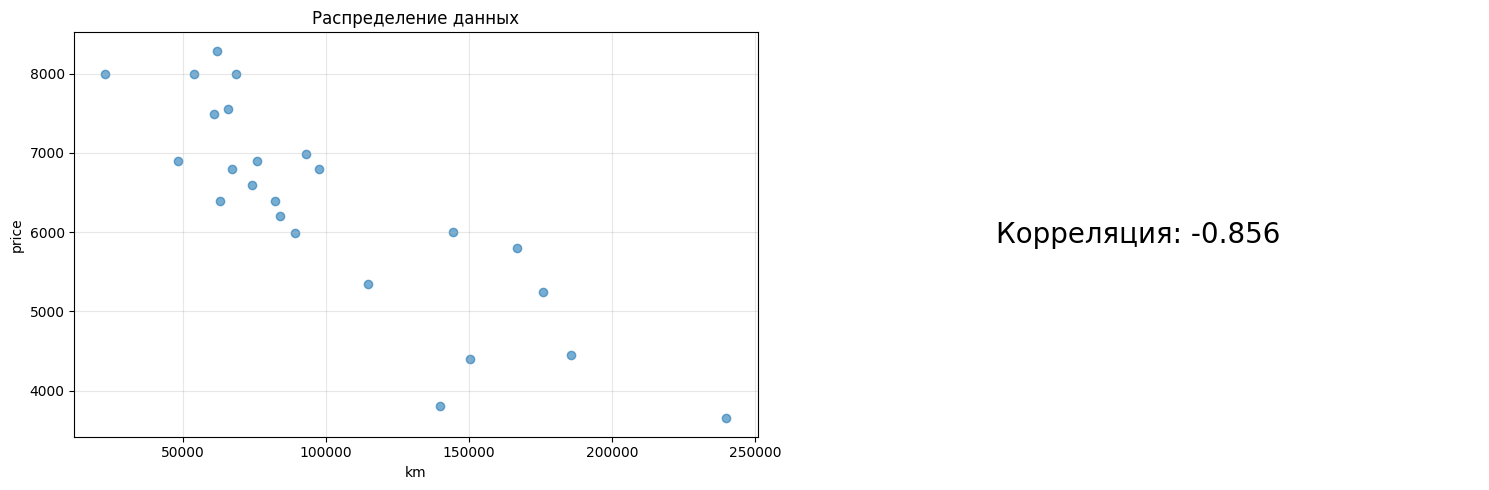


Количество признаков: 1
Количество образцов: 24

Коэффициенты регрессии
y = 0.0000 + -0.8561 * X

Коэффициенты:
  w1 = -0.8561
  bias (intercept) = 0.0000

Метрики качества
R² коэффициент: 0.7330
MSE (Mean Squared Error): 445645.2451
RMSE (Root MSE): 667.5667
MAE (Mean Absolute Error): 557.8384


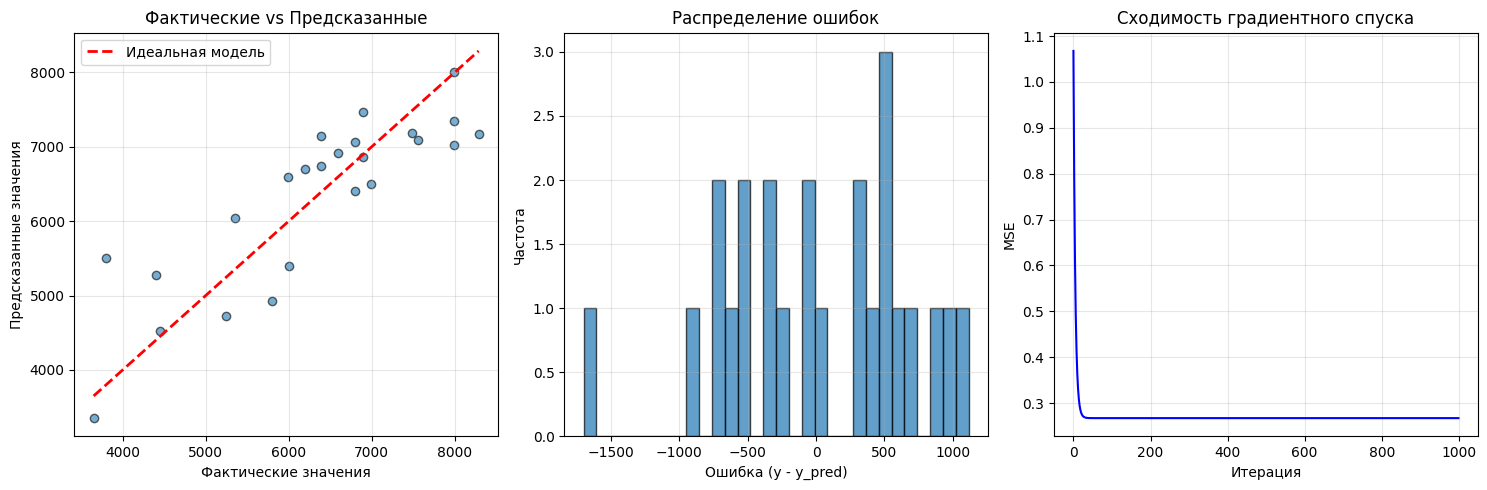

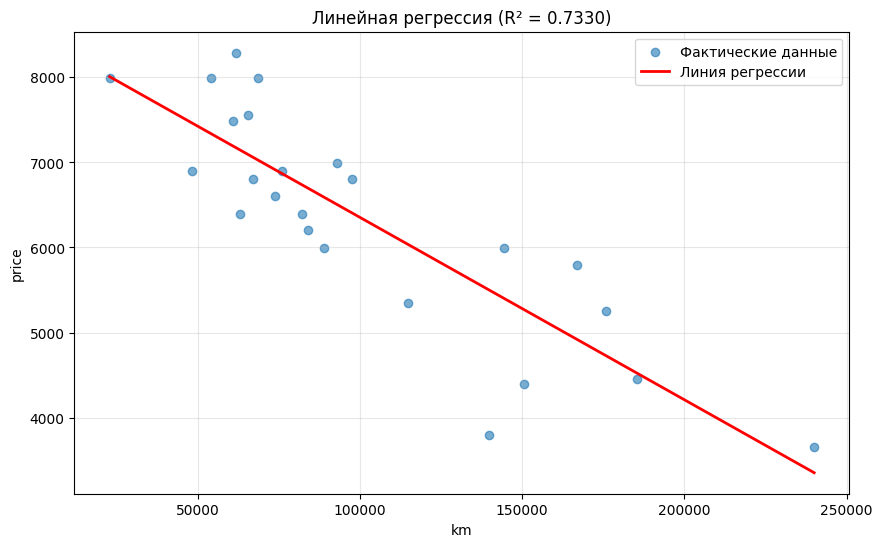


Тестирование метода predict() с новыми данными

Предсказания для новых значений:
X               y_pred         
------------------------------
22899.00        8008.44        
131449.50       5680.14        
240000.00       3351.85        
101066.25       6331.83        

Проверка работы с нормализацией

Параметры нормализации (сохранены при обучении):
X_mean: [101066.25]
X_std: [51565.18991064]
y_mean: 6331.8333
y_std: 1291.8689

Модель корректно работает с исходными (ненормированными) данными!
Внутренне она нормализует данные, а затем денормализует предсказания.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

class LinearRegression:

    def __init__(self, learning_rate=0.01, n_iterations=1000, fit_intercept=True):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.fit_intercept = fit_intercept
        self.weights = None
        self.bias = None

        self.X_mean = None
        self.X_std = None
        self.y_mean = None
        self.y_std = None

        self.loss_history = []

    def _normalize(self, X, normalize_y=False):
        X_normalized = (X - self.X_mean) / self.X_std
        if normalize_y:
            y_normalized = (self.y - self.y_mean) / self.y_std
            return X_normalized, y_normalized
        return X_normalized

    def _denormalize(self, y_pred_normalized):
        return y_pred_normalized * self.y_std + self.y_mean

    def _add_bias_column(self, X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y).reshape(-1, 1)

        n_samples, n_features = X.shape

        self.X_mean = X.mean(axis=0)
        self.X_std = X.std(axis=0)
        self.X_std = np.where(self.X_std == 0, 1, self.X_std)

        self.y_mean = y.mean()
        self.y_std = y.std()
        self.y_std = np.where(self.y_std == 0, 1, self.y_std)

        X_norm = self._normalize(X)
        y_norm = (y - self.y_mean) / self.y_std

        if self.fit_intercept:
            X_norm = self._add_bias_column(X_norm)
            n_features += 1

        self.weights = np.random.randn(n_features, 1) * 0.01

        for epoch in range(self.n_iterations):
            y_hat = np.dot(X_norm, self.weights)

            error = y_hat - y_norm

            gradients = (1 / n_samples) * np.dot(X_norm.T, error)

            self.weights -= self.learning_rate * gradients

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

        return self

    def predict(self, X):
        if self.weights is None:
            raise ValueError("Модель еще не обучена. Вызовите fit() перед predict().")

        X = np.array(X)

        X_norm = self._normalize(X)

        if self.fit_intercept:
            X_norm = self._add_bias_column(X_norm)

        y_pred_norm = np.dot(X_norm, self.weights)

        y_pred = self._denormalize(y_pred_norm)

        return y_pred.flatten()

    def score(self, X, y):
        y_pred = self.predict(X)
        y = np.array(y).flatten()

        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)

        return 1 - (ss_res / ss_tot)

    def get_coefficients(self):
        if self.weights is None:
            raise ValueError("Модель еще не обучена.")

        if self.fit_intercept:
            bias = self.weights[0, 0]
            weights = self.weights[1:, 0]
            return weights, bias
        else:
            return self.weights.flatten(), None

    def plot_loss(self):
        plt.figure(figsize=(10, 6))
        plt.plot(self.loss_history)
        plt.xlabel('Итерация')
        plt.ylabel('MSE')
        plt.title('Сходимость градиентного спуска')
        plt.grid(True)
        plt.show()


df = pd.read_csv('data.csv')

plt.figure(figsize=(15, 5))

if df.shape[1] == 2:
    plt.subplot(1, 2, 1)
    plt.scatter(df.iloc[:, 0], df.iloc[:, 1], alpha=0.6)
    plt.xlabel(df.columns[0])
    plt.ylabel(df.columns[1])
    plt.title('Распределение данных')
    plt.grid(True, alpha=0.3)

    corr = df.iloc[:, 0].corr(df.iloc[:, 1])
    plt.subplot(1, 2, 2)
    plt.text(0.5, 0.5, f'Корреляция: {corr:.3f}',
             ha='center', va='center', fontsize=20)
    plt.axis('off')
else:
    pd.plotting.scatter_matrix(df, alpha=0.3, figsize=(12, 8))

plt.tight_layout()
plt.show()

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

print(f"\nКоличество признаков: {X.shape[1]}")
print(f"Количество образцов: {X.shape[0]}")

model = LinearRegression(learning_rate=0.1, n_iterations=1000, fit_intercept=True)
model.fit(X, y)

print("\n" + "=" * 60)
print("Коэффициенты регрессии")
print("=" * 60)

weights, bias = model.get_coefficients()

if X.shape[1] == 1:
    print(f"y = {bias:.4f} + {weights[0]:.4f} * X")
else:
    equation = "y = "
    if bias is not None:
        equation += f"{bias:.4f} "
    for i, w in enumerate(weights):
        equation += f"+ {w:.4f} * X{i+1} "
    print(equation)

print(f"\nКоэффициенты:")
for i, w in enumerate(weights):
    print(f"  w{i+1} = {w:.4f}")
if bias is not None:
    print(f"  bias (intercept) = {bias:.4f}")

print("\n" + "=" * 60)
print("Метрики качества")
print("=" * 60)

r2 = model.score(X, y)
print(f"R² коэффициент: {r2:.4f}")

y_pred = model.predict(X)

mse_final = np.mean((y - y_pred) ** 2)
rmse_final = np.sqrt(mse_final)
mae_final = np.mean(np.abs(y - y_pred))

print(f"MSE (Mean Squared Error): {mse_final:.4f}")
print(f"RMSE (Root MSE): {rmse_final:.4f}")
print(f"MAE (Mean Absolute Error): {mae_final:.4f}")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(y, y_pred, alpha=0.6, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Идеальная модель')
plt.xlabel('Фактические значения')
plt.ylabel('Предсказанные значения')
plt.title('Фактические vs Предсказанные')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
residuals = y - y_pred
plt.hist(residuals, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Ошибка (y - y_pred)')
plt.ylabel('Частота')
plt.title('Распределение ошибок')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(model.loss_history, color='blue')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Сходимость градиентного спуска')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if X.shape[1] == 1:
    plt.figure(figsize=(10, 6))
    sorted_idx = np.argsort(X.flatten())
    plt.scatter(X, y, alpha=0.6, label='Фактические данные')
    plt.plot(X[sorted_idx], y_pred[sorted_idx], 'r-', linewidth=2, label='Линия регрессии')
    plt.xlabel(df.columns[0])
    plt.ylabel(df.columns[1])
    plt.title(f'Линейная регрессия (R² = {r2:.4f})')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

print("\n" + "=" * 60)
print("Тестирование метода predict() с новыми данными")
print("=" * 60)

if X.shape[1] == 1:
    test_values = np.array([
        [X.min()],
        [(X.min() + X.max()) / 2],
        [X.max()],
        [X.mean()]
    ])

    predictions = model.predict(test_values)

    print(f"\nПредсказания для новых значений:")
    print(f"{'X':<15} {'y_pred':<15}")
    print("-" * 30)
    for val, pred in zip(test_values.flatten(), predictions):
        print(f"{val:<15.2f} {pred:<15.2f}")
else:
    print(f"\nСравнение фактических и предсказанных значений (первые 5 строк):")
    print(f"{'№':<5} {'Факт':<15} {'Pred':<15} {'Ошибка':<15}")
    print("-" * 55)
    for i in range(min(5, len(y))):
        print(f"{i:<5} {y[i]:<15.2f} {y_pred[i]:<15.2f} {abs(y[i] - y_pred[i]):<15.2f}")

print("\n" + "=" * 60)
print("Проверка работы с нормализацией")
print("=" * 60)

print(f"\nПараметры нормализации (сохранены при обучении):")
print(f"X_mean: {model.X_mean}")
print(f"X_std: {model.X_std}")
print(f"y_mean: {model.y_mean:.4f}")
print(f"y_std: {model.y_std:.4f}")

print(f"\nМодель корректно работает с исходными (ненормированными) данными!")
print(f"Внутренне она нормализует данные, а затем денормализует предсказания.")
